# AUC & ROC creation

In [1]:
# import findspark
import findspark
# initialize findspark with spark directory
findspark.init()
# import pyspark
import pyspark
# create spark contextp
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/17 22:12:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
25/12/17 22:12:15 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
25/12/17 22:12:15 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


In [2]:
spark

In [15]:
from pyspark.sql import functions as F

# Load and rename columns per model
lr_df = spark.read.parquet("../Cleaned_data/Model_Predictions/LR_predictions") \
    .withColumnRenamed("probability", "lr_prediction")

gbt_df = spark.read.parquet("../Cleaned_data/Model_Predictions/GBT_predictions") \
    .withColumnRenamed("probability", "gbt_prediction")

genlr_df = spark.read.parquet("../Cleaned_data/Model_Predictions/GENLR_predictions") \
    .withColumnRenamed("probability", "genlr_prediction")

svm_df = spark.read.parquet("../Cleaned_data/Model_Predictions/SVM_predictions") \
    .withColumnRenamed("rawPrediction", "svm_prediction")

In [16]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Initialize evaluator
evaluator_auc = BinaryClassificationEvaluator(
    labelCol="financing_next_period", 
    metricName="areaUnderROC"  # Metric for AUC
)

# Compute AUC for each model
lr_auc = evaluator_auc.setRawPredictionCol("lr_prediction").evaluate(lr_df)
gbt_auc = evaluator_auc.setRawPredictionCol("gbt_prediction").evaluate(gbt_df)
genlr_auc = evaluator_auc.setRawPredictionCol("genlr_prediction").evaluate(genlr_df)
svm_auc = evaluator_auc.setRawPredictionCol("svm_prediction").evaluate(svm_df)

# Print AUC values
print(f"AUC for Logistic Regression (LR): {lr_auc:.2f}")
print(f"AUC for Gradient Boosted Trees (GBT): {gbt_auc:.2f}")
print(f"AUC for Generalized Linear Regression (GENLR): {genlr_auc:.2f}")
print(f"AUC for Support Vector Machine (SVM): {svm_auc:.2f}")

AUC for Logistic Regression (LR): 0.52
AUC for Gradient Boosted Trees (GBT): 0.59
AUC for Generalized Linear Regression (GENLR): 0.67
AUC for Support Vector Machine (SVM): 0.67


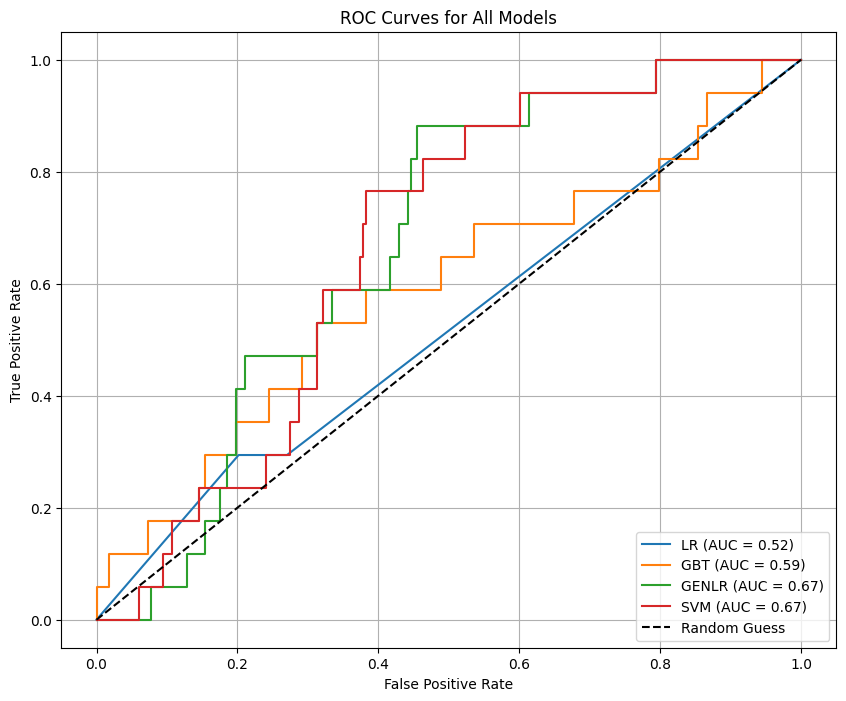

In [18]:
# Convert to Pandas
lr_pd = lr_df.toPandas()
gbt_pd = gbt_df.toPandas()
genlr_pd = genlr_df.toPandas()
svm_pd = svm_df.toPandas()

# Extract true labels and positive class probabilities
y_true = lr_pd["financing_next_period"]
lr_scores = lr_pd["lr_prediction"].apply(lambda x: float(x[1]))
gbt_scores = gbt_pd["gbt_prediction"].apply(lambda x: float(x[1]))
genlr_scores = genlr_pd["genlr_prediction"].apply(lambda x: float(x[1]))
svm_scores = svm_pd["svm_prediction"].apply(lambda x: float(x[1]))

# Compute ROC curves and AUC scores
from sklearn.metrics import roc_curve, auc

lr_fpr, lr_tpr, _ = roc_curve(y_true, lr_scores)
lr_auc = auc(lr_fpr, lr_tpr)

gbt_fpr, gbt_tpr, _ = roc_curve(y_true, gbt_scores)
gbt_auc = auc(gbt_fpr, gbt_tpr)

genlr_fpr, genlr_tpr, _ = roc_curve(y_true, genlr_scores)
genlr_auc = auc(genlr_fpr, genlr_tpr)

svm_fpr, svm_tpr, _ = roc_curve(y_true, svm_scores)
svm_auc = auc(svm_fpr, svm_tpr)

# Plot ROC Curves
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.plot(lr_fpr, lr_tpr, label=f"LR (AUC = {lr_auc:.2f})")
plt.plot(gbt_fpr, gbt_tpr, label=f"GBT (AUC = {gbt_auc:.2f})")
plt.plot(genlr_fpr, genlr_tpr, label=f"GENLR (AUC = {genlr_auc:.2f})")
plt.plot(svm_fpr, svm_tpr, label=f"SVM (AUC = {svm_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All Models")
plt.legend(loc="lower right")
plt.grid()
plt.show()